# FetoWatch AI - Model Comparison and Evaluation

## Objective

The objective of this notebook is to train, compare, and
evaluate multiple machine learning classification algorithms
for fetal health classification.

The models will be evaluated using multiple performance
metrics, including:

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. Confusion Matrix

We will also use cross-validation to assess model stability
and identify a suitable candidate for further optimization.

The final model selection will consider the performance of
all three classes, particularly the Pathological class.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    cross_validate,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

## 1. Loading Preprocessed Data

We load the training and testing datasets generated in
Notebook 2.

The same training and testing split will be used across
all candidate models to ensure a fair comparison.

In [3]:
data_dir = Path("../data/processed")

X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

y_train = pd.read_csv(data_dir / "y_train.csv").squeeze()
y_test = pd.read_csv(data_dir / "y_test.csv").squeeze()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1690, 21)
Testing features: (423, 21)
Training target: (1690,)
Testing target: (423,)


In [4]:
print("Training classes:", sorted(y_train.unique()))
print("Testing classes:", sorted(y_test.unique()))

print("Feature columns match:", list(X_train.columns) == list(X_test.columns))

Training classes: [np.int64(0), np.int64(1), np.int64(2)]
Testing classes: [np.int64(0), np.int64(1), np.int64(2)]
Feature columns match: True


## 2. Evaluation Metrics

We evaluate each model using multiple metrics.

- Accuracy: Overall proportion of correctly classified records.
- Precision: Proportion of predicted positive classifications
  that are correct.
- Recall: Proportion of actual positive classifications
  correctly identified.
- F1-score: Harmonic mean of precision and recall.

Since this is a multiclass classification problem, we use
macro-averaged precision, recall, and F1-score.

Macro averaging calculates the metric independently for
each class and then takes the unweighted average.

This prevents the majority class from dominating the
overall evaluation.

## 3. Defining Candidate Models

We evaluate different classification algorithms representing
linear, distance-based, tree-based, and ensemble approaches.

Models that require feature scaling are placed inside
pipelines with StandardScaler.

Tree-based models are trained without feature scaling.

In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

## 4. Cross-Validation

We use Stratified K-Fold cross-validation to evaluate
the models on different subsets of the training data.

Stratification preserves the class proportions in each fold.

We use five folds and macro F1-score as the primary
cross-validation metric.

The test dataset remains untouched during this stage.

In [6]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

In [8]:
cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision_macro"].mean(),
        "Recall": scores["test_recall_macro"].mean(),
        "Macro F1": scores["test_f1_macro"].mean(),
        "F1 Std": scores["test_f1_macro"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,Macro F1,F1 Std
0,XGBoost,0.941420,0.910263,0.881122,0.893413,0.019748
1,Gradient Boosting,0.936095,0.906734,0.865171,0.883341,0.017857
2,Random Forest,0.936095,0.905713,0.864594,0.881306,0.019160
3,Decision Tree,0.915976,0.853745,0.858685,0.854309,0.030219
4,SVM,0.904142,0.858291,0.784875,0.816534,0.019769
5,KNN,0.892308,0.833696,0.757192,0.789376,0.015727
6,Logistic Regression,0.887574,0.792342,0.769474,0.779127,0.027290


## 5. Comparing Cross-Validation Performance

We visualize the macro F1-score of each model to compare
their performance across the cross-validation folds.

The standard deviation is also considered to understand
the consistency of the models.

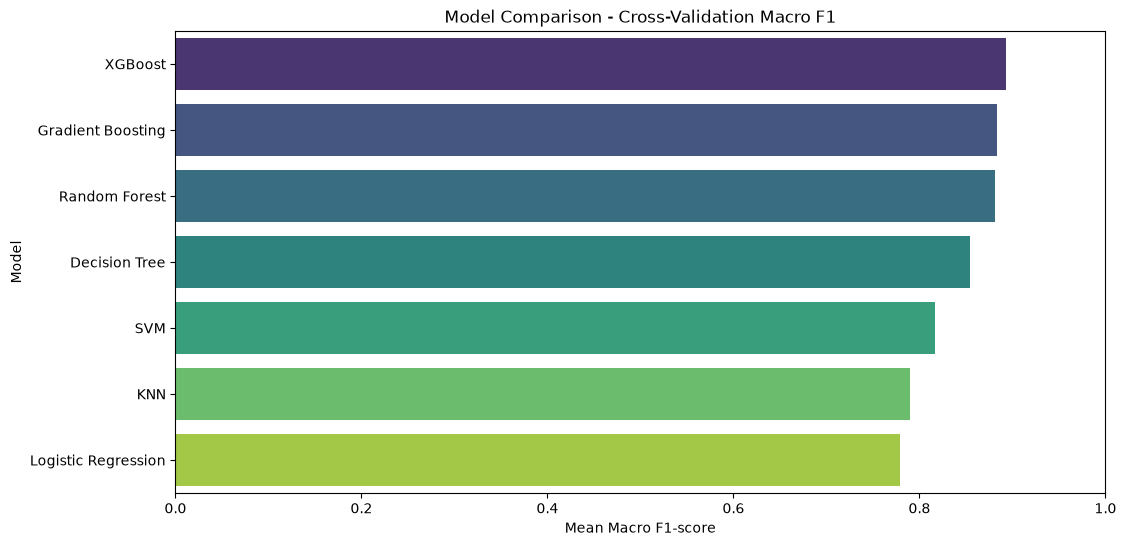

In [9]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=cv_results_df.sort_values("Macro F1", ascending=False),
    x="Macro F1",
    y="Model",
    hue="Model",
    legend=False,
    palette="viridis"
)

plt.title("Model Comparison - Cross-Validation Macro F1")
plt.xlabel("Mean Macro F1-score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

## 6. Test Set Evaluation

After comparing the models using cross-validation on the
training data, we train each candidate model on the complete
training dataset.

We then evaluate each model on the held-out test dataset.

The test dataset is used only for this final comparison,
not for model tuning or hyperparameter selection.

In [10]:
test_results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    trained_models[name] = model

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

test_results_df = pd.DataFrame(test_results)

test_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,Macro F1
0,XGBoost,0.964539,0.967827,0.919490,0.941475
1,Gradient Boosting,0.959811,0.968366,0.903259,0.930276
2,Random Forest,0.952719,0.952218,0.878464,0.910508
3,Decision Tree,0.933806,0.898206,0.871344,0.884311
4,SVM,0.903073,0.867060,0.766353,0.807513
5,Logistic Regression,0.888889,0.821399,0.761253,0.788471
6,KNN,0.888889,0.844717,0.722461,0.772010


## 7. Detailed Classification Evaluation

We inspect the classification report and confusion matrix
to understand how each class is being predicted.

Special attention is given to the Pathological class,
because incorrectly classifying a pathological record as
Normal is an important error to investigate.

In [11]:
class_names = [
    "Normal",
    "Suspect",
    "Pathological"
]

best_cv_model_name = (
    cv_results_df.sort_values(
        "Macro F1", ascending=False
    ).iloc[0]["Model"]
)

best_model = trained_models[best_cv_model_name]

best_predictions = best_model.predict(X_test)

print("Selected candidate:", best_cv_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

Selected candidate: XGBoost
              precision    recall  f1-score   support

      Normal       0.96      0.99      0.98       330
     Suspect       0.94      0.79      0.86        58
Pathological       1.00      0.97      0.99        35

    accuracy                           0.96       423
   macro avg       0.97      0.92      0.94       423
weighted avg       0.96      0.96      0.96       423



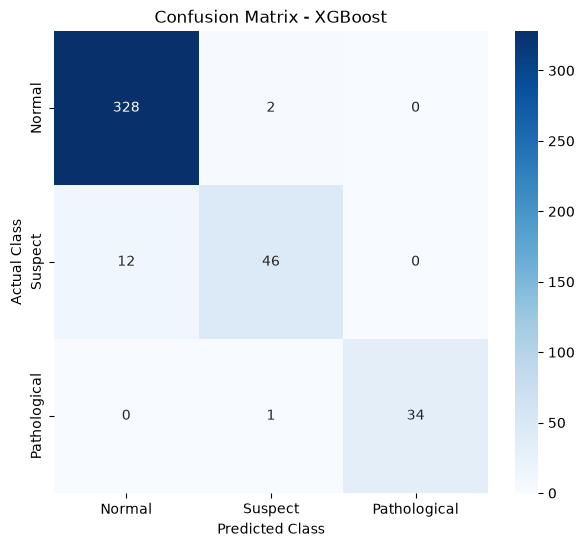

In [12]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"Confusion Matrix - {best_cv_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

## 8. XGBoost Hyperparameter Optimization

We perform hyperparameter optimization for XGBoost
using RandomizedSearchCV.

The search uses stratified cross-validation and macro
F1-score as the optimization metric.

The test dataset is not used during hyperparameter tuning.

In [13]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

param_distributions = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6, 7],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

In [14]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1_macro",
    cv=cv,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("Best parameters:")
print(xgb_search.best_params_)

print("Best cross-validation Macro F1:")
print(xgb_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'subsample': 0.7, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best cross-validation Macro F1:
0.8982716971633622


## 9. Evaluation of Tuned XGBoost

We evaluate the optimized XGBoost model using the
held-out test dataset.

Its performance is compared with the initial XGBoost
model and the other candidate models.

In [15]:
tuned_xgb = xgb_search.best_estimator_

tuned_predictions = tuned_xgb.predict(X_test)

print(
    classification_report(
        y_test,
        tuned_predictions,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

print("Tuned XGBoost Accuracy:",
      accuracy_score(y_test, tuned_predictions))

print("Tuned XGBoost Macro F1:",
      f1_score(y_test, tuned_predictions, average="macro"))

              precision    recall  f1-score   support

      Normal       0.95      1.00      0.97       330
     Suspect       0.98      0.74      0.84        58
Pathological       1.00      0.94      0.97        35

    accuracy                           0.96       423
   macro avg       0.98      0.89      0.93       423
weighted avg       0.96      0.96      0.96       423

Tuned XGBoost Accuracy: 0.9574468085106383
Tuned XGBoost Macro F1: 0.9290327570870557


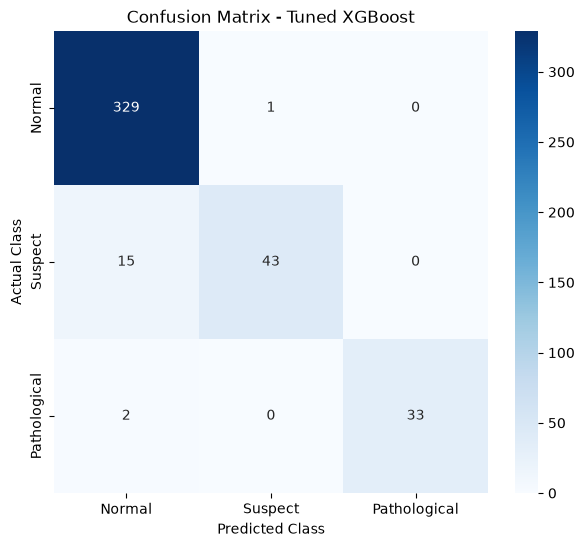

In [16]:
tuned_cm = confusion_matrix(
    y_test,
    tuned_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    tuned_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Tuned XGBoost")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

## 10. Final Model Comparison and Observations

We summarize the performance of the candidate models
and the optimized XGBoost model.

The final analysis considers:

- Cross-validation Macro F1-score.
- Cross-validation variability.
- Held-out test accuracy.
- Held-out test Macro F1-score.
- Class-wise precision and recall.
- Pathological class recall.
- Confusion matrix observations.

The model selection decision should consider the balance
between overall performance and class-wise classification
behavior.

The selected model will be examined further using SHAP
explainability in the next notebook.

In [17]:
comparison_summary = test_results_df.copy()

comparison_summary = pd.concat([
    comparison_summary,
    pd.DataFrame([{
        "Model": "Tuned XGBoost",
        "Accuracy": accuracy_score(y_test, tuned_predictions),
        "Precision": precision_score(
            y_test, tuned_predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, tuned_predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, tuned_predictions, average="macro", zero_division=0
        )
    }])
], ignore_index=True)

comparison_summary.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,Macro F1
0,XGBoost,0.964539,0.967827,0.919490,0.941475
1,Gradient Boosting,0.959811,0.968366,0.903259,0.930276
2,Tuned XGBoost,0.957447,0.976047,0.893735,0.929033
3,Random Forest,0.952719,0.952218,0.878464,0.910508
4,Decision Tree,0.933806,0.898206,0.871344,0.884311
5,SVM,0.903073,0.867060,0.766353,0.807513
6,Logistic Regression,0.888889,0.821399,0.761253,0.788471
7,KNN,0.888889,0.844717,0.722461,0.772010
